In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

orders_df = pd.read_csv("store_orders.csv")
customers_df = pd.read_csv("store_customers.csv")

con = sqlite3.connect("store.db")
orders_df.to_sql("orders", con, if_exists="replace", index=False)
customers_df.to_sql("customers", con, if_exists="replace", index=False)

pd.read_sql("SELECT name FROM sqlite_master", con)

,name
0,orders
1,customers


In [2]:
pd.read_sql("SELECT * FROM orders LIMIT 5", con)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [3]:
step3 = pd.read_sql("""
    SELECT *
    FROM orders
    WHERE amount > 100
    ORDER BY amount DESC
""", con)
step3.head()

,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22


In [4]:
print("All amounts > 100:", (step3["amount"] > 100).all())
print("Descending:", step3["amount"].is_monotonic_decreasing)
print("Top amount:", step3["amount"].iloc[0])

All amounts > 100: True
Descending: True
Top amount: 499.0


In [5]:
step4 = pd.read_sql("""
    SELECT category,
           COUNT(*) AS n,
           ROUND(AVG(amount), 2) AS avg_amount
    FROM orders
    GROUP BY category
    ORDER BY avg_amount DESC
""", con)
step4

,category,n,avg_amount
0,electronics,60,190.57
1,furniture,46,146.25
2,office,51,30.13
3,snacks,43,14.62


Electronics earns the most per order, averaging far more per order than furniture, office supplies, or snacks.

In [6]:
step5 = pd.read_sql("""
    SELECT c.city,
           ROUND(SUM(o.amount), 2) AS total_spend
    FROM orders AS o
    JOIN customers AS c
      ON o.customer_id = c.customer_id
    GROUP BY c.city
    ORDER BY total_spend DESC
""", con)
step5

,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


In [7]:
print("orders rows:", pd.read_sql("SELECT COUNT(*) AS n FROM orders", con)["n"][0])
print("joined rows:", pd.read_sql("""
    SELECT COUNT(*) AS n
    FROM orders AS o
    JOIN customers AS c ON o.customer_id = c.customer_id
""", con)["n"][0])

orders rows: 200
joined rows: 195


### row-count audit
There are 200 rows in orders and 195 after the join. JOIN drops rows where there is no match between customer_id and customer. 5 orders have a customer_id that does not exist in the customers table. This means that the city totals in step 5 undercount the total spend.

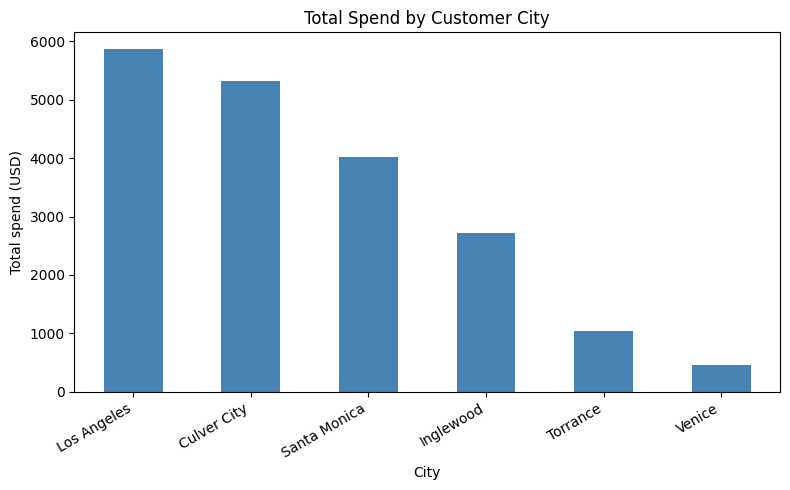

In [8]:
ax = step5.plot(kind="bar", x="city", y="total_spend", legend=False, figsize=(8, 5), color="steelblue")
ax.set_title("Total Spend by Customer City")
ax.set_xlabel("City")
ax.set_ylabel("Total spend (USD)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### question
Which city has customers that spend the most per order?

In [9]:
pd.read_sql("""
    SELECT c.city,
           COUNT(*) AS n_orders,
           ROUND(AVG(o.amount), 2) AS avg_order
    FROM orders AS o
    JOIN customers AS c ON o.customer_id = c.customer_id
    GROUP BY c.city
    ORDER BY avg_order DESC
""", con)

,city,n_orders,avg_order
0,Los Angeles,46,127.46
1,Inglewood,27,100.68
2,Santa Monica,42,95.67
3,Culver City,58,91.67
4,Torrance,14,74.09
5,Venice,8,57.80


### answer
Los Angeles has customers that spend the most per order with an average of 127.46. Inglewood is second at 100.68 but only has 27 orders and Culver City has the most orders (58) but a lower average of 91.67. When you compare it to step 5 it shows that the results of step 5 are driven by order volume and order size.

### ethics and safety
For privacy customer names and IDs should be removed. Someone could reidentify a person from their name or city and order details. Only aggregated results should be shown. Very small groups should also be combined because it is easier to identify a customer from a very small group(like of 1 or 2 people in small cities). This notebook does not dump the customers table.